In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

Saving lung_cancer_dataset.csv to lung_cancer_dataset.csv


In [ ]:
df = pd.read_csv("../../data/lung_cancer_dataset.csv")

In [ ]:
df.head()

,patient_id,age,gender,pack_years,radon_exposure,asbestos_exposure,secondhand_smoke_exposure,copd_diagnosis,alcohol_consumption,family_history,lung_cancer
0,100000,69,Male,66.025244,High,No,No,Yes,Moderate,No,No
1,100001,32,Female,12.780800,High,No,Yes,Yes,Moderate,Yes,Yes
2,100002,89,Female,0.408278,Medium,Yes,Yes,Yes,NaN,No,Yes
3,100003,78,Female,44.065232,Low,No,Yes,No,Moderate,No,Yes
4,100004,38,Female,44.432440,Medium,Yes,No,Yes,NaN,Yes,Yes


In [ ]:
df["lung_cancer"].value_counts()

,count
lung_cancer,
Yes,34364
No,15636


In [ ]:
X= df[["age", "pack_years"]]
y = df["lung_cancer"]



In [ ]:
y = y.map({"No":0, "Yes":1})

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

In [ ]:
print(y_prob[:10])

[0.49836344 0.68427867 0.76974163 0.8072349  0.57774316 0.77068417
 0.4624542  0.62352556 0.83303575 0.73968576]


In [ ]:
y_pred = model.predict(X_test)

print(y_pred[:10])


[0 1 1 1 1 1 0 1 1 1]


In [ ]:
from sklearn.metrics import log_loss

loss = log_loss(y_test, y_prob)

print("Log Loss:", loss)

Log Loss: 0.5913162500611643


In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print (cm)

[[ 459 2659]
 [ 257 6625]]


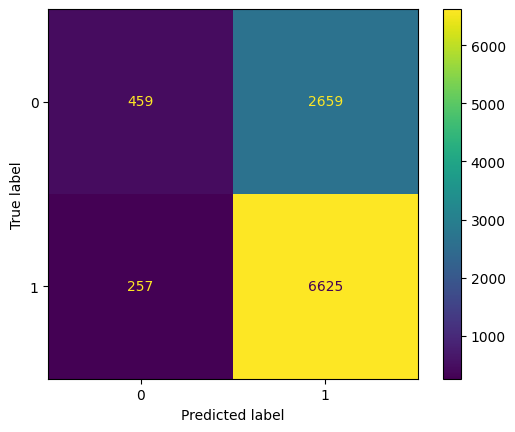

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7084
